# 04 · H1: does the EEG change as awakening approaches?

**H1:** within participants, posterior delta power and the aperiodic exponent fall from E2 to E4.
Linear mixed model per measure over E2-E4: time (epoch centre, per 30 s) + site + artifact rate,
random intercepts for participant and for awakening within participant. Holm across the two primary tests.

**RQ3 (exploratory):** does the slope depend on report richness (log word count of the transcription)?

Everything below the primary section is exploratory and labelled so.

In [1]:
# Bootstrap: same cell in every notebook. On Colab: mount Drive, get the (public) repo, install extras.
import os, sys, subprocess
REPO_URL = "https://github.com/sanjanasinghx/dream2image-es606.git"
if "google.colab" in sys.modules and not os.environ.get("D2I_HEADLESS"):  # headless = run by d2i.runner
    from google.colab import drive
    drive.mount("/content/drive")
    REPO = "<repo>"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", REPO_URL, REPO], check=True)
    else:
        subprocess.run(["git", "-C", REPO, "fetch", "-q", "origin"], check=True)
        subprocess.run(["git", "-C", REPO, "reset", "-q", "--hard", "origin/main"], check=True)
    freeze = lambda: subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
    before = freeze()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{REPO}/requirements-colab.txt"], check=True)
    if freeze() != before:  # e.g. numpy upgraded under an already-loaded copy -> broken imports
        print("Packages changed: restarting the runtime. When it reconnects, Run all again.")
        os.kill(os.getpid(), 9)
else:
    REPO = os.path.abspath("..")
sys.path.insert(0, REPO)
from d2i import env
cfg = env.load_config()
rng = env.seed_everything(cfg["seed"])
print("data root:", env.data_root())

data root: <data root>


In [2]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from d2i import data, stats
hc = cfg["h1"]
der, tables, figs = env.path(cfg, "derived"), env.path(cfg, "results") / "tables", env.path(cfg, "results") / "figures"
tables.mkdir(exist_ok=True); figs.mkdir(exist_ok=True)
words = {m["sample_id"]: len((m.get("transcription") or "").split()) for m in data.load_meta(cfg)}
def prep(df):
    d = df[df.epoch.isin(hc["epochs"])].copy()
    d["time30"] = d.center_s / 30.0
    d["richness_z"] = np.log(d.sample_id.map(words))
    d["richness_z"] = (d.richness_z - d.richness_z.mean()) / d.richness_z.std()
    return d
roi = prep(pd.read_csv(der / "features_roi.csv"))
long = prep(pd.read_csv(der / "features_long.csv"))
long = long[long.ok]
print(f"ROI rows {len(roi)}, awakenings {roi.sample_id.nunique()}, participants {roi.participant.nunique()}")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


ROI rows 345, awakenings 118, participants 37


## 1. Primary test (confirmatory)

In [3]:
rows = []
for y in hc["primary"]:
    rows.append(stats.fit_trend(roi, y, hc["covariates"]))
    rows.append(stats.fit_trend(roi, y, [c for c in hc["covariates"] if c != "reject_rate"]))
prim = pd.DataFrame(rows)
main = prim.covariates == "+".join(hc["covariates"])
prim.loc[main, "p_holm"] = stats.holm(prim.loc[main, "p"])
prim.to_csv(tables / "h1_primary.csv", index=False)
print(prim[["y", "covariates", "estimate", "ci_low", "ci_high", "std_estimate", "p", "p_holm",
            "n_awakenings", "n_participants", "converged"]].round(4).to_string(index=False))

           y       covariates  estimate  ci_low  ci_high  std_estimate      p  p_holm  n_awakenings  n_participants  converged
logpow_delta site+reject_rate    0.0285 -0.0018   0.0588        0.0491 0.0651  0.0651           118              37       True
logpow_delta             site    0.0293 -0.0008   0.0595        0.0505 0.0566     NaN           118              37       True
 ap_exponent site+reject_rate    0.0430  0.0110   0.0751        0.1417 0.0085  0.0171           118              37       True
 ap_exponent             site    0.0439  0.0120   0.0758        0.1446 0.0070     NaN           118              37       True


## 2. RQ3: does the slope depend on report richness? (exploratory)

In [4]:
rq3 = pd.DataFrame([stats.fit_trend(roi, y, hc["covariates"], interaction="richness_z") for y in hc["primary"]])
rq3.to_csv(tables / "rq3_richness.csv", index=False)
print("word count: median", int(np.median(list(words.values()))), "range", min(words.values()), "-", max(words.values()))
print(rq3[["y", "term", "estimate", "ci_low", "ci_high", "p", "converged"]].round(4).to_string(index=False))

word count: median 46 range 10 - 638
           y              term  estimate  ci_low  ci_high      p  converged
logpow_delta time30:richness_z    0.0100 -0.0204   0.0404 0.5183       True
 ap_exponent time30:richness_z    0.0103 -0.0219   0.0426 0.5295       True


## 3. All bands, posterior ROI, and the channel map (exploratory, FDR)

In [5]:
measures = [c for c in roi.columns if c.startswith("logpow_")] + ["ap_exponent", "ap_offset"]
expl = pd.DataFrame([stats.fit_trend(roi, y, hc["covariates"]) for y in measures])
expl["p_fdr"] = stats.fdr_bh(expl.p)
expl.to_csv(tables / "h1_exploratory_roi.csv", index=False)
print(expl[["y", "std_estimate", "ci_low", "ci_high", "p", "p_fdr"]].round(4).to_string(index=False))

chan = []
for ch, g in long.groupby("channel"):
    for y in ["logpow_delta", "logpow_alpha", "logpow_beta", "ap_exponent"]:
        chan.append({"channel": ch, **stats.fit_trend(g, y, hc["covariates"])})
chan = pd.DataFrame(chan)
chan["p_fdr"] = stats.fdr_bh(chan.p)
chan.to_csv(tables / "h1_exploratory_channels.csv", index=False)
print("channel x measure tests surviving FDR:", int((chan.p_fdr < hc["alpha"]).sum()), "of", len(chan))

           y  std_estimate  ci_low  ci_high      p  p_fdr
logpow_delta        0.0491 -0.0018   0.0588 0.0651 0.0911
logpow_theta        0.0443 -0.0047   0.0594 0.0947 0.1045
logpow_alpha       -0.1195 -0.1280  -0.0237 0.0044 0.0199
logpow_sigma       -0.0461 -0.0600   0.0056 0.1045 0.1045
 logpow_beta       -0.0542 -0.0529  -0.0080 0.0078 0.0199
 ap_exponent        0.1417  0.0110   0.0751 0.0085 0.0199
   ap_offset        0.0634  0.0007   0.0761 0.0459 0.0803


channel x measure tests surviving FDR: 24 of 64


## 4. Figure

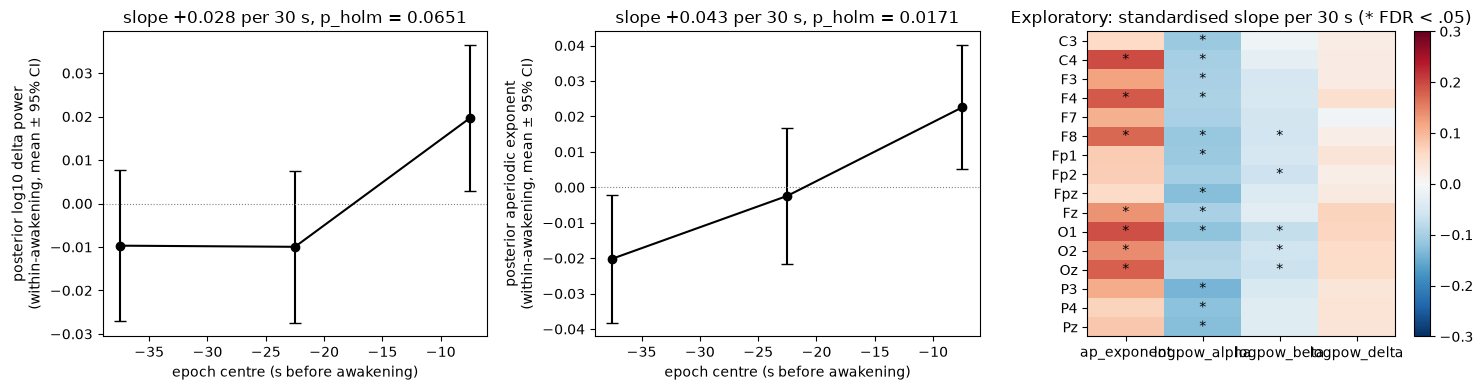

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
labels = {"logpow_delta": "posterior log10 delta power", "ap_exponent": "posterior aperiodic exponent"}
for a, y in zip(ax[:2], hc["primary"]):
    d = roi.dropna(subset=[y]).copy()
    d["centered"] = d[y] - d.groupby("sample_id")[y].transform("mean")  # within-awakening change
    m = d.groupby("center_s").centered.agg(["mean", "sem"])
    a.errorbar(m.index, m["mean"], yerr=1.96 * m["sem"], marker="o", color="k", capsize=4)
    a.axhline(0, color="grey", lw=.8, ls=":")
    r = prim[(prim.y == y) & main].iloc[0]
    a.set(xlabel="epoch centre (s before awakening)", ylabel=f"{labels[y]}\n(within-awakening, mean ± 95% CI)",
          title=f"slope {r.estimate:+.3f} per 30 s, p_holm = {r.p_holm:.3g}")
piv = chan.pivot(index="channel", columns="y", values="std_estimate")
im = ax[2].imshow(piv.values, cmap="RdBu_r", vmin=-.3, vmax=.3, aspect="auto")
sig = chan.pivot(index="channel", columns="y", values="p_fdr").values < hc["alpha"]
for i, j in zip(*np.where(sig)):
    ax[2].text(j, i, "*", ha="center", va="center")
ax[2].set(xticks=range(piv.shape[1]), xticklabels=piv.columns, yticks=range(piv.shape[0]), yticklabels=piv.index,
          title="Exploratory: standardised slope per 30 s (* FDR < .05)")
plt.colorbar(im, ax=ax[2])
fig.tight_layout(); fig.savefig(figs / "h1_trend.pdf"); fig.savefig(figs / "h1_trend.png", dpi=150)

## 5. Post hoc: split by awakening type (exploratory)

**Added after seeing section 1**, so this is an explanation to be tested elsewhere, not a confirmatory result.
Sleep-onset (SO) awakenings wake people shortly after they fall asleep, so their last 45 s may track the
descent into sleep rather than anything that precedes waking. SO awakenings exist only in the `subject` site,
so site is dropped as a covariate within SO.

  awakening_type            y  std_estimate  ci_low  ci_high      p  p_fdr  n_awakenings  n_participants
           other logpow_delta       -0.0367 -0.0645   0.0168 0.2507 0.3582            50              32
           other logpow_alpha       -0.0718 -0.1302   0.0418 0.3134 0.3582            50              32
           other  logpow_beta       -0.0026 -0.0309   0.0279 0.9206 0.9206            50              32
           other  ap_exponent       -0.0753 -0.0655   0.0183 0.2699 0.3582            50              32
sleep onset (SO) logpow_delta        0.1481  0.0262   0.1108 0.0015 0.0040            68              18
sleep onset (SO) logpow_alpha       -0.1810 -0.1617  -0.0308 0.0039 0.0079            68              18
sleep onset (SO)  logpow_beta       -0.1243 -0.0848  -0.0204 0.0014 0.0040            68              18
sleep onset (SO)  ap_exponent        0.3676  0.0511   0.1403 0.0000 0.0002            68              18


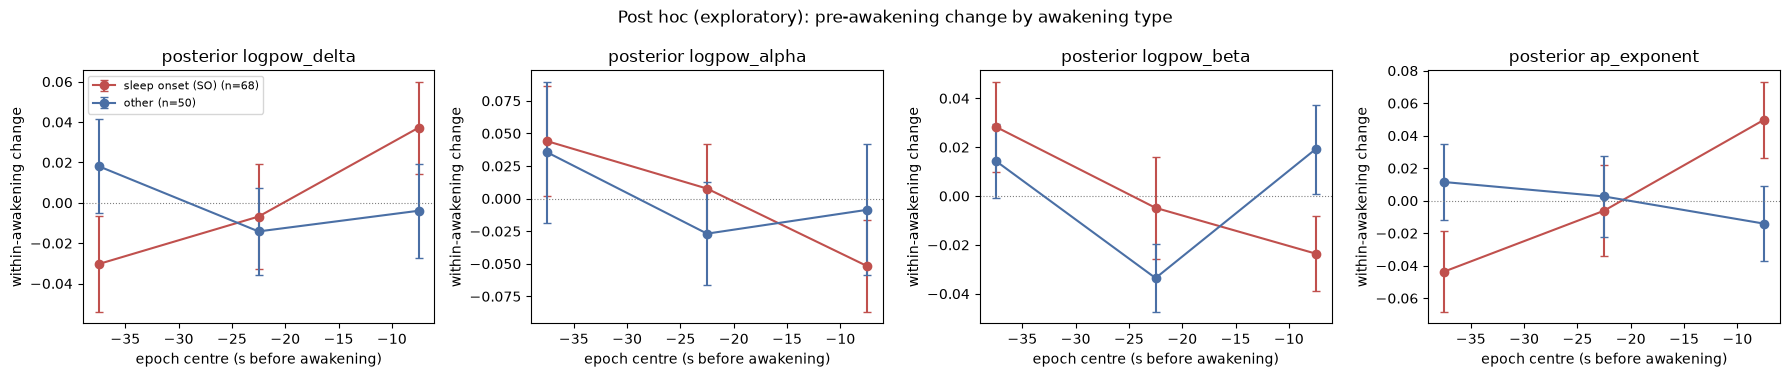

In [7]:
roi["awakening_type"] = np.where(roi.tag_class == "SO", "sleep onset (SO)", "other")
split = []
for t, g in roi.groupby("awakening_type"):
    cov = [c for c in hc["covariates"] if c != "site" or g.site.nunique() > 1]
    for y in ["logpow_delta", "logpow_alpha", "logpow_beta", "ap_exponent"]:
        split.append({"awakening_type": t, **stats.fit_trend(g, y, cov)})
split = pd.DataFrame(split)
split["p_fdr"] = stats.fdr_bh(split.p)
split.to_csv(tables / "h1_posthoc_awakening_type.csv", index=False)
print(split[["awakening_type", "y", "std_estimate", "ci_low", "ci_high", "p", "p_fdr", "n_awakenings",
             "n_participants"]].round(4).to_string(index=False))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, y in zip(ax, ["logpow_delta", "logpow_alpha", "logpow_beta", "ap_exponent"]):
    for t, c in [("sleep onset (SO)", "#c0504d"), ("other", "#4a6fa5")]:
        d = roi[(roi.awakening_type == t)].dropna(subset=[y]).copy()
        d["centered"] = d[y] - d.groupby("sample_id")[y].transform("mean")
        m = d.groupby("center_s").centered.agg(["mean", "sem"])
        a.errorbar(m.index, m["mean"], yerr=1.96 * m["sem"], marker="o", color=c, capsize=3,
                   label=f"{t} (n={d.sample_id.nunique()})")
    a.axhline(0, color="grey", lw=.8, ls=":")
    a.set(xlabel="epoch centre (s before awakening)", title=f"posterior {y}", ylabel="within-awakening change")
ax[0].legend(fontsize=8)
fig.suptitle("Post hoc (exploratory): pre-awakening change by awakening type")
fig.tight_layout(); fig.savefig(figs / "h1_posthoc_awakening_type.pdf"); fig.savefig(figs / "h1_posthoc_awakening_type.png", dpi=150)

## 6. Sensitivity of the time effect (added after review)

**Not pre-specified.** The models above give each participant and awakening its own intercept but one shared
slope. When slopes differ between people, that understates the uncertainty of the time effect
(Barr et al. 2013). Two checks, for the pooled sample and for each group separately:

- the same model plus a **random time slope per participant**;
- a **model-free sign-flip test**: least-squares slope within each awakening, averaged per participant,
  signs flipped at random over participants (no model assumptions, participants as the unit).

Groups: all; sleep onset (SO, `subject` site only); `subject` site without SO (Morning, NREM, REM);
`case` site (awakening stage not tagged). The sign-flip test does not adjust for covariates.

In [8]:
srng = np.random.default_rng(cfg["seed"])
groups = {"all": (roi, hc["covariates"]),
          "sleep onset (SO)": (roi[roi.tag_class == "SO"], ["reject_rate"]),
          "subject site, not SO": (roi[(roi.site == "subject") & (roi.tag_class != "SO")], ["reject_rate"]),
          "case site (stage untagged)": (roi[roi.site == "case"], ["reject_rate"])}
sens = []
for name, (d, cov) in groups.items():
    for y in ["ap_exponent", "logpow_delta", "logpow_alpha"]:
        sens.append({"group": name, "model": "random intercepts (pre-specified)", **stats.fit_trend(d, y, cov)})
        sens.append({"group": name, "model": "+ random slope per participant",
                     **stats.fit_trend(d, y, cov, random_slope=True)})
        sens.append({"group": name, "model": "sign-flip over participants",
                     **stats.signflip_slopes(d, y, hc["n_signflip"], srng)})
sens = pd.DataFrame(sens)
sens.to_csv(tables / "h1_sensitivity.csv", index=False)
print(sens[["group", "y", "model", "estimate", "p", "n_awakenings", "n_participants", "converged"]]
      .round(4).to_string(index=False))
env.write_manifest(cfg, "04_h1", [tables / f for f in ["h1_primary.csv", "rq3_richness.csv", "h1_exploratory_roi.csv",
                                                       "h1_exploratory_channels.csv", "h1_posthoc_awakening_type.csv",
                                                       "h1_sensitivity.csv"]])

                     group            y                             model  estimate      p  n_awakenings  n_participants converged
                       all  ap_exponent random intercepts (pre-specified)    0.0430 0.0085           118              37      True
                       all  ap_exponent    + random slope per participant    0.0356 0.0745           118              37      True
                       all  ap_exponent       sign-flip over participants    0.0258 0.2595           118              37       NaN
                       all logpow_delta random intercepts (pre-specified)    0.0285 0.0651           118              37      True
                       all logpow_delta    + random slope per participant    0.0160 0.4420           118              37      True
                       all logpow_delta       sign-flip over participants    0.0155 0.4756           118              37       NaN
                       all logpow_alpha random intercepts (pre-specified)   -0.0758

PosixPath('<data root>/results/logs/manifest_04_h1.json')